# Complexity-03c — Carte du zoo de complexite (C#)

**Navigation** : [README de la serie](README.md) · [version Python](Complexity-03c-ComplexityZoo-Navigation-Python.ipynb) · [03 — hierarchie temporelle](Complexity-03-HierarchieTemporelle-CSharp.ipynb) · [04d — secretaire matroidal](Complexity-04d-Secretaire-Matroidal-CSharp.ipynb)

Ce carnet est le **jumeau C#** du carnet Python homonyme. Il refait les memes experiences avec la
bibliotheque standard .NET uniquement (aucun paquet externe, aucune restauration NuGet) : les
algorithmes sont reecrits, pas appeles depuis une bibliotheque. Les generateurs pseudo-aleatoires
de .NET et de NumPy ne produisent pas les memes suites : les instances different, donc les valeurs
numeriques imprimees different de la version Python. Les **budgets**, les **tailles** et les
**protocoles de mesure** sont identiques.

Le fil du carnet suit une seule question : quelles aretes de la carte P / NP / PSPACE sont
**demontrees dans ce carnet** (par une experience executable), lesquelles sont **citees** (theoreme
du cours, non rejoue ici), et lesquelles sont **ouvertes** (personne ne sait).

## Ce que le carnet mesure, et ce qu'il ne mesure pas

Trois familles d'experiences, dans cet ordre :

1. **Les inclusions basses** — atteignabilite dirigee decidee par un DFS deterministe, puis le meme
   probleme accepte par un verificateur a memoire logarithmique qui lit un certificat une seule fois.
   L'accord des deux cotes est mesure, et un faux certificat est presente au verificateur pour
   verifier qu'il le refuse.
2. **Le saut P vers NP** — 2-SAT decide en temps lineaire par le graphe d'implications (Kosaraju),
   3-SAT decide par DPLL au voisinage du seuil de satisfiabilite. Le compteur de noeuds de DPLL est
   la metrique retenue : il est deterministe, alors que le temps depend de la machine hote.
3. **Les deux mondes d'oracles** — une diagonalisation jouet qui construit un oracle ou une machine
   polynomiale se trompe sur un mot, et un oracle complet ou la meme machine repond juste avec une
   seule requete.

**Aucune de ces experiences ne demontre une separation de classes de complexite.** Elles montrent
des comportements sur des familles finies d'instances, ce qui est exactement ce qu'une mesure peut
montrer. La section finale explicite cette limite au lieu de la contourner.

In [1]:
// Outillage commun : tout le carnet n'utilise que la bibliotheque standard .NET.
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text;
using System.Globalization;
using System.Diagnostics;
using Microsoft.DotNet.Interactive.Formatting;

// Parametres de batch : le carnet est execute de bout en bout par papermill/nbconvert.
string BATCH_MODE = "true";

// Graine unique : toutes les instances du carnet descendent de ce generateur.
var Rng = new Random(20260925);

// Chronometre : minimum de plusieurs passes, pour amortir le bruit de la machine hote.
(double Min, T Valeur) Chrono<T>(Func<T> f, int repetitions = 3) {
    double best = double.MaxValue; T r = default;
    for (int i = 0; i < repetitions; i++) {
        var sw = Stopwatch.StartNew(); r = f(); sw.Stop();
        best = Math.Min(best, sw.Elapsed.TotalSeconds);
    }
    return (best, r);
}

// Affichage SVG natif : le type ci-dessous declare le MIME exact du contenu.
record SvgMarkup(string Content);
// image/svg+xml (et non text/html) : seul ce MIME rend la figure comme image, pas comme page.
Formatter.Register<SvgMarkup>((v, ctx) => { ctx.Writer.Write(v.Content); return true; }, "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(SvgMarkup), new[] { "image/svg+xml" });
string F(double x) => x.ToString("0.##", CultureInfo.InvariantCulture);
string Esc(string s) => System.Security.SecurityElement.Escape(s) ?? "";

// Nuage de points en echelle log-log : deux familles de tailles tres differentes sur un meme axe.
string NuageSvg((double[] X, double[] Y, string Label, string Couleur)[] series, string titre, string xlab, string ylab) {
    const int W = 860, H = 390, L = 95, R = 210, Top = 55, Bot = 75;
    var xsAll = series.SelectMany(s => s.X).Where(v => v > 0).ToArray();
    var ysAll = series.SelectMany(s => s.Y).Where(v => v > 0).ToArray();
    double lx0 = Math.Log10(xsAll.Min()), lx1 = Math.Log10(xsAll.Max());
    double ly0 = Math.Floor(Math.Log10(ysAll.Min())), ly1 = Math.Ceiling(Math.Log10(ysAll.Max()));
    if (ly1 <= ly0) ly1 = ly0 + 1;
    double X(double v) => L + (Math.Log10(v) - lx0) / (lx1 - lx0) * (W - L - R);
    double Y(double v) => H - Bot - (Math.Log10(v) - ly0) / (ly1 - ly0) * (H - Top - Bot);
    var b = new StringBuilder();
    b.Append($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}' viewBox='0 0 {W} {H}'>");
    b.Append("<rect width='100%' height='100%' fill='white'/>");
    b.Append($"<text x='{(L + W - R) / 2}' y='26' text-anchor='middle' font-family='sans-serif' font-size='14'>{Esc(titre)}</text>");
    b.Append($"<path d='M {L} {Top} V {H - Bot} H {W - R}' stroke='black' fill='none'/>");
    for (int i = 0; i <= 5; i++) {
        double xv = Math.Pow(10, lx0 + (lx1 - lx0) * i / 5.0);
        b.Append($"<text x='{F(X(xv))}' y='{H - Bot + 20}' text-anchor='middle' font-family='sans-serif' font-size='11'>{F(xv)}</text>");
    }
    for (int k = (int)ly0; k <= (int)ly1; k++) {
        double yv = Math.Pow(10, k);
        b.Append($"<text x='{L - 10}' y='{F(Y(yv) + 4)}' text-anchor='end' font-family='sans-serif' font-size='11'>{F(yv)}</text>");
        b.Append($"<path d='M {L} {F(Y(yv))} H {W - R}' stroke='#dddddd' fill='none'/>");
    }
    int rang = 0;
    foreach (var s in series) {
        var pts = string.Join(" ", s.X.Select((xv, i) => $"{F(X(xv))},{F(Y(s.Y[i]))}"));
        b.Append($"<polyline points='{pts}' fill='none' stroke='{s.Couleur}' stroke-width='2'/>");
        for (int i = 0; i < s.X.Length; i++) {
            b.Append($"<circle cx='{F(X(s.X[i]))}' cy='{F(Y(s.Y[i]))}' r='4' fill='{s.Couleur}'/>");
        }
        int ly = Top + 14 + rang * 22;
        b.Append($"<rect x='{W - R + 12}' y='{ly - 9}' width='11' height='11' fill='{s.Couleur}'/>");
        b.Append($"<text x='{W - R + 29}' y='{ly}' font-family='sans-serif' font-size='12'>{Esc(s.Label)}</text>");
        rang++;
    }
    b.Append($"<text x='{(L + W - R) / 2}' y='{H - 18}' text-anchor='middle' font-family='sans-serif' font-size='12'>{Esc(xlab)}</text>");
    b.Append($"<text transform='translate(24,{(Top + H - Bot) / 2}) rotate(-90)' text-anchor='middle' font-family='sans-serif' font-size='12'>{Esc(ylab)}</text>");
    b.Append("</svg>");
    return b.ToString();
}

Console.WriteLine("Outillage en place : generateur a graine fixe, chronometre, rendu SVG opaque.");

Outillage en place : generateur a graine fixe, chronometre, rendu SVG opaque.


## 1. Les inclusions basses, du cote machine

On commence par le probleme le plus simple de la carte : **existe-t-il un chemin du sommet source
au sommet cible** dans un graphe dirige. Trois faits du cours se laissent toucher ici :

- un parcours en profondeur le decide en temps polynomial, avec une pile dont la taille mesure
  l'espace explore ;
- le meme probleme est dans **NL**, parce qu'un certificat (un chemin) se verifie en lisant le
  certificat une seule fois avec deux mots de memoire de travail ;
- les deux reponses doivent coincider sur toute la famille d'instances testee.

La premiere cellule construit les graphes et mesure la pile du DFS.

In [2]:
// --- 1a. Atteignabilite : le DFS deterministe et sa pile ---
(bool Atteint, int PileMax) DfsAtteignable(Dictionary<int, List<int>> adj, int s, int t) {
    var vu = new HashSet<int> { s };
    var pile = new Stack<int>();
    pile.Push(s);
    int pileMax = 1;
    while (pile.Count > 0) {
        int u = pile.Pop();
        if (u == t) return (true, pileMax);
        if (!adj.TryGetValue(u, out var sortants)) continue;
        foreach (int v in sortants) {
            if (vu.Add(v)) { pile.Push(v); pileMax = Math.Max(pileMax, pile.Count); }
        }
    }
    return (false, pileMax);
}

// Graphe dirige aleatoire : densite aretes par sommet, boucles possibles, comme la source Python.
Dictionary<int, List<int>> GrapheAleatoire(int n, int densite) {
    var adj = new Dictionary<int, List<int>>();
    for (int u = 0; u < n; u++) {
        if (!adj.ContainsKey(u)) adj[u] = new List<int>();
        for (int k = 0; k < densite; k++) adj[u].Add(Rng.Next(n));
    }
    return adj;
}

Console.WriteLine($"{"n",5} {"atteint",8} {"pile max",9} {"temps ms",10}");
foreach (int n in new[] { 40, 100, 250, 600 }) {
    var adj = GrapheAleatoire(n, 4);
    var (duree, res) = Chrono(() => DfsAtteignable(adj, 0, n - 1));
    Console.WriteLine($"{n,5} {res.Atteint,8} {res.PileMax,9} {duree * 1e3,10:F3}");
}

    n  atteint  pile max   temps ms


   40     True         8      0,002


  100     True        40      0,015


  250     True       109      0,021


  600     True       262      0,061


La colonne **pile max** est l'espace explore par le parcours : elle croit avec le graphe, et
c'est cette croissance qui distingue un algorithme de decision d'un simple temoin. Le temps suit la
taille du graphe, non sa structure — un DFS visite chaque sommet au plus une fois.

La cellule suivante prend le probleme par l'autre bout : un **certificat** est presente a un
verificateur qui n'a pas le droit de le relire. Sa memoire de travail se reduit a deux mots — le
sommet courant et le nombre de pas — et pourtant il doit decider la meme langue que le DFS.

In [3]:
// --- 1b. Le verificateur NL : certificat lu UNE fois, deux mots de memoire ---
(bool Accepte, int Pas) VerificateurNl(Dictionary<int, List<int>> adj, int s, int t, IEnumerable<int> certificat) {
    // Memoire de travail hors certificat : u (sommet courant) et pas (compteur).
    // Le certificat est un flux parcouru une seule fois, jamais relu.
    int n = adj.Count;
    int u = s;
    int pas = 0;
    foreach (int v in certificat) {
        pas++;
        if (pas > n + 1) return (false, pas);
        if (!adj.TryGetValue(u, out var sortants) || !sortants.Contains(v)) return (false, pas);
        u = v;
        if (u == t) return (true, pas);
    }
    return (u == t, pas);
}

// Le prouveur, hors machine : un chemin quelconque s->t, trouve par parcours en largeur.
List<int> CheminTemoins(Dictionary<int, List<int>> adj, int s, int t) {
    var file = new Queue<int>();
    file.Enqueue(s);
    var pere = new Dictionary<int, int?> { [s] = null };
    while (file.Count > 0) {
        int u = file.Dequeue();
        if (u == t) {
            var chemin = new List<int>();
            int? c = u;
            while (c is not null) { chemin.Add(c.Value); c = pere[c.Value]; }
            chemin.Reverse();
            return chemin;
        }
        if (!adj.TryGetValue(u, out var sortants)) continue;
        foreach (int v in sortants) if (!pere.ContainsKey(v)) { pere[v] = u; file.Enqueue(v); }
    }
    return null;
}

Console.WriteLine($"{"n",5} {"atteint",8} {"verif NL",9} {"pas",5} {"mots",6}");
bool accordTotal = true;
Dictionary<int, List<int>> dernierAdj = null;
List<int> dernierTemoin = null;
foreach (int n in new[] { 40, 100, 250, 600 }) {
    var adj = GrapheAleatoire(n, 2);
    var (_, okDfs) = Chrono(() => DfsAtteignable(adj, 0, n - 1));
    var temoin = CheminTemoins(adj, 0, n - 1);
    bool okNl; int pas;
    if (temoin is not null) (okNl, pas) = VerificateurNl(adj, 0, n - 1, temoin.Skip(1));
    else (okNl, pas) = (false, n + 2);
    bool accord = okDfs.Atteint == okNl;
    accordTotal &= accord;
    Console.WriteLine($"{n,5} {okDfs.Atteint,8} {okNl,9} {pas,5} {2,6}   accord={accord}");
    // On ne retient que les graphes ou un chemin existe : le controle negatif a besoin d'un
    // vrai temoin a amputer, pas d'un graphe sans chemin.
    if (temoin is not null) { dernierAdj = adj; dernierTemoin = temoin; }
}
Console.WriteLine($"Accord verificateur/DFS sur toute la famille : {accordTotal}");

// Un faux temoin : le chemin du dernier graphe qui en admettait un, ampute de son arrivee.
// Le verificateur doit le refuser -- c'est la seconde moitie de "exactement".
var faux = dernierTemoin.Skip(1).Take(dernierTemoin.Count - 2).ToList();
var (okFaux, _) = VerificateurNl(dernierAdj, 0, dernierAdj.Count - 1, faux);
Console.WriteLine($"Faux temoin (arrivee amputee) refuse par le verificateur : {!okFaux}");

    n  atteint  verif NL   pas   mots


   40     True      True     2      2   accord=True


  100     True      True     3      2   accord=True


  250     True      True     7      2   accord=True


  600    False     False   602      2   accord=True


Accord verificateur/DFS sur toute la famille : True


Faux temoin (arrivee amputee) refuse par le verificateur : True


Deux resultats comptent ici, et un troisieme est un controle negatif.

L'**accord** est la partie positive : sur chaque taille, le decideur et le verificateur rendent le
meme verdict. Le **nombre de pas** est la partie quantitative : il reste borne par la taille du
certificat, ce qui est la definition meme d'une verification a ressources limitees.

Le **faux temoin** est le controle negatif, et c'est celui qui manque le plus souvent. Un
verificateur qui accepte tout accepte aussi les vrais certificats : sans un certificat trafique
refuse, l'accord mesure ne dit rien. Ici le chemin est ampute de son dernier sommet — il ne
« arrive » plus nulle part — et le verificateur le rejette.

## 2. Le saut P vers NP

Meme forme de question, deux problemes. **2-SAT** se decide en temps lineaire : chaque clause
devient deux implications, la satisfiabilite se lit sur les composantes fortement connexes, et deux
litteraux opposes dans une meme composante signifient contradiction. **3-SAT** ne se decide pas par
un algorithme lineaire connu : DPLL propage les clauses unitaires et branche, et son arbre de
recherche croit avec le nombre de variables.

La metrique retenue pour 3-SAT est le **nombre de noeuds explores**, pas le temps. C'est un choix
deliberе : le temps depend de la charge de la machine hote, alors que le nombre de noeuds depend
seulement de l'instance et de la strategie de branchement.

In [4]:
// --- 1c. P contre NP : 2-SAT lineaire, 3-SAT exponentiel ---
(bool Sat, Dictionary<int, bool> Val) DeuxSat(List<(int A, int B)> clauses, int nbVar) {
    // Kosaraju sur le graphe d'implications : temps lineaire en le nombre de clauses.
    int n = nbVar;
    int Lit(int l) => l > 0 ? l - 1 : Math.Abs(l) - 1 + n;
    int Neg(int i) => i < n ? i + n : i - n;
    var adj = new List<int>[2 * n];
    var radj = new List<int>[2 * n];
    for (int i = 0; i < 2 * n; i++) { adj[i] = new List<int>(); radj[i] = new List<int>(); }
    foreach (var (a, b) in clauses) {
        int la = Lit(a), lb = Lit(b);
        // (a ou b) = (non-a -> b) et (non-b -> a)
        adj[Neg(la)].Add(lb); adj[Neg(lb)].Add(la);
        radj[lb].Add(Neg(la)); radj[la].Add(Neg(lb));
    }
    var vu = new bool[2 * n];
    var ordre = new List<int>();
    void Dfs1(int u) { vu[u] = true; foreach (int v in adj[u]) if (!vu[v]) Dfs1(v); ordre.Add(u); }
    for (int s = 0; s < 2 * n; s++) if (!vu[s]) Dfs1(s);
    var comp = Enumerable.Repeat(-1, 2 * n).ToArray();
    void Dfs2(int u, int c) { comp[u] = c; foreach (int v in radj[u]) if (comp[v] == -1) Dfs2(v, c); }
    int cc = 0;
    for (int i = ordre.Count - 1; i >= 0; i--) { int s = ordre[i]; if (comp[s] == -1) { Dfs2(s, cc); cc++; } }
    for (int i = 0; i < n; i++) if (comp[i] == comp[i + n]) return (false, null);
    var val = new Dictionary<int, bool>();
    for (int i = 0; i < n; i++) val[i + 1] = comp[i] > comp[i + n];
    return (true, val);
}

(bool Sat, Dictionary<int, bool> Sol, int Noeuds) TroisSatDpll(List<List<int>> clauses, int nbVar) {
    // DPLL : propagation de unite puis branchement, avec compteur de noeuds explores.
    // Le compteur est la metrique deterministe -- le temps, lui, varie d'une machine a l'autre.
    int noeuds = 0;
    Dictionary<int, bool> Resoudre(Dictionary<int, bool> partiel, List<List<int>> restantes) {
        noeuds++;
        while (true) {
            var unitaires = restantes.Where(c => c.Count == 1).Select(c => c[0]).ToList();
            if (unitaires.Count == 0) break;
            int l = unitaires[0];
            var nouvelles = new List<List<int>>();
            foreach (var c in restantes) {
                if (c.Contains(l)) continue;
                if (c.Contains(-l)) {
                    var c2 = c.Where(x => x != -l).ToList();
                    if (c2.Count == 0) return null;
                    nouvelles.Add(c2);
                } else nouvelles.Add(c);
            }
            restantes = nouvelles;
            partiel = new Dictionary<int, bool>(partiel) { [Math.Abs(l)] = l > 0 };
        }
        if (restantes.Count == 0) return partiel;
        // Clause vide en entree (jamais propagee) : la formule est non satisfiable.
        if (restantes.Any(c => c.Count == 0)) return null;
        int choixL = restantes[0][0];
        foreach (int choix in new[] { choixL, -choixL }) {
            var cand = restantes.Where(c => !c.Contains(choix))
                                .Select(c => c.Where(x => x != -choix).ToList()).ToList();
            var p2 = new Dictionary<int, bool>(partiel) { [Math.Abs(choix)] = choix > 0 };
            var r = Resoudre(p2, cand);
            if (r is not null) return r;
        }
        return null;
    }
    var sol = Resoudre(new Dictionary<int, bool>(), clauses.Select(c => c.ToList()).ToList());
    return (sol is not null, sol, noeuds);
}

// L'arete P inclus dans NP : verifier un certificat est polynomial.
bool Verifier3Sat(List<List<int>> clauses, Dictionary<int, bool> solution) =>
    clauses.All(c => c.Any(x => (x > 0) == solution.GetValueOrDefault(Math.Abs(x), false)));

List<(int, int)> Instance2Sat(int n, int m) {
    var cl = new List<(int, int)>();
    for (int k = 0; k < m; k++) {
        int a = Rng.Next(1, n + 1) * (Rng.NextDouble() < 0.5 ? 1 : -1);
        int b = Rng.Next(1, n + 1) * (Rng.NextDouble() < 0.5 ? 1 : -1);
        cl.Add((a, b));
    }
    return cl;
}

// 3-CNF aleatoire (litteral 50/50). La densite est fixee par l'appelant : au voisinage du
// seuil de satisfiabilite, les instances aleatoires sont les plus dures pour DPLL.
List<List<int>> Instance3SatPlantee(int n, int m) {
    var cl = new List<List<int>>();
    for (int k = 0; k < m; k++) {
        var c = new List<int>();
        while (c.Count < 3) {
            int v = Rng.Next(1, n + 1);
            if (!c.Any(x => Math.Abs(x) == v)) c.Add(Rng.NextDouble() < 0.5 ? v : -v);
        }
        cl.Add(c);
    }
    return cl;
}

List<List<int>> InstanceSatisfiable(int n, int m, int essaisMax = 12) {
    var cl = new List<List<int>>();
    for (int e = 0; e < essaisMax; e++) {
        cl = Instance3SatPlantee(n, m);
        var (sat, _, _) = TroisSatDpll(cl, n);
        if (sat) return cl;
    }
    return cl;
}

// 2-SAT : le probleme de P -- de 50 a 800 variables (seize fois plus), le temps suit de pres.
Console.WriteLine("2-SAT (Kosaraju) -- moyenne sur 5 instances :");
var temps2Sat = new List<(double N, double T)>();
foreach (int n in new[] { 50, 200, 800 }) {
    double cumul = 0.0;
    for (int k = 0; k < 5; k++) {
        var clauses2 = Instance2Sat(n, 3 * n);
        var (d2, _) = Chrono(() => DeuxSat(clauses2, n));
        cumul += d2;
    }
    temps2Sat.Add((n, cumul / 5));
    Console.WriteLine($"  n={n,4}   {cumul / 5 * 1e3,8:F3} ms");
}

// 3-SAT : le probleme NP-complet -- meme question existentielle, densite au seuil.
Console.WriteLine("3-SAT (DPLL, densite 4.6n) -- moyenne sur 20 instances :");
var tailles = new[] { 10, 15, 20, 25, 30 };
var noeudsMoyens = new Dictionary<int, double>();
var tempsMoyens = new Dictionary<int, double>();
foreach (int n in tailles) {
    long totalNoeuds = 0;
    double cumul = 0.0;
    for (int k = 0; k < 20; k++) {
        var clauses3 = Instance3SatPlantee(n, (int)(4.6 * n));
        var (d3, res3) = Chrono(() => TroisSatDpll(clauses3, n));
        totalNoeuds += res3.Noeuds;
        cumul += d3;
    }
    noeudsMoyens[n] = totalNoeuds / 20.0;
    tempsMoyens[n] = cumul / 20.0;
    Console.WriteLine($"  n={n,3}   noeuds DPLL : {noeudsMoyens[n],8:F1}   {tempsMoyens[n] * 1e3,8:F3} ms");
}

int n0 = tailles[0], n1 = tailles[^1];
double facteurNoeuds = Math.Pow(noeudsMoyens[n1] / noeudsMoyens[n0], 1.0 / (n1 - n0));
double facteurTemps = Math.Pow(tempsMoyens[n1] / tempsMoyens[n0], 1.0 / (n1 - n0));
Console.WriteLine($"Facteur de croissance par variable ajoutee (noeuds explores, deterministe) : ~{facteurNoeuds:F2}x");
Console.WriteLine($"Facteur de croissance par variable ajoutee (temps) : ~{facteurTemps:F2}x");

// L'arete P inclus dans NP, dans l'autre sens : le certificat se verifie en temps polynomial.
int certificats = 0;
for (int k = 0; k < 20; k++) {
    var clauses3 = InstanceSatisfiable(12, 4 * 12);
    var (_, res3) = Chrono(() => TroisSatDpll(clauses3, 12));
    if (res3.Sat && res3.Sol is not null && Verifier3Sat(clauses3, res3.Sol)) certificats++;
}
Console.WriteLine($"Certificats 3-SAT verifies en temps polynomial par Verifier3Sat : {certificats} / 20");

2-SAT (Kosaraju) -- moyenne sur 5 instances :


  n=  50      0,032 ms


  n= 200      0,099 ms


  n= 800      0,443 ms


3-SAT (DPLL, densite 4.6n) -- moyenne sur 20 instances :


  n= 10   noeuds DPLL :      9,3      0,192 ms


... (3 outputs left out)

  n= 30   noeuds DPLL :     64,2      4,924 ms


Facteur de croissance par variable ajoutee (noeuds explores, deterministe) : ~1,10x


Facteur de croissance par variable ajoutee (temps) : ~1,18x


Certificats 3-SAT verifies en temps polynomial par Verifier3Sat : 20 / 20


Les deux familles de tailles ne se comportent pas de la meme facon, et c'est ce que le carnet
peut affirmer : un algorithme **lineaire** parcourt le graphe d'implications sans revenir en arriere,
tandis que DPLL construit un arbre dont la taille croit avec le nombre de variables. Les facteurs de
croissance imprimes resument cette difference sur la plage mesuree.

Ils ne la **demontrent** pas. Un facteur extrait de cinq tailles est une tendance locale, pas une
borne asymptotique ; et aucun jeu fini d'instances ne separe P de NP, puisque ce sont des classes
infinies. La figure suivante rend la tendance visible, la section finale dit ce qu'elle vaut.

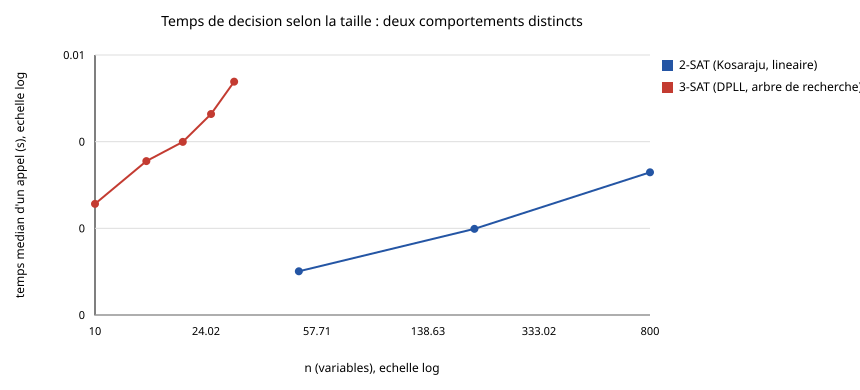

Figure : points mesures, axes logarithmiques, fond blanc opaque.


In [5]:
// Figure : temps de decision des deux familles, echelles doubles-log.
var figZoo = NuageSvg(new[] {
        (temps2Sat.Select(z => z.N).ToArray(), temps2Sat.Select(z => z.T).ToArray(),
         "2-SAT (Kosaraju, lineaire)", "#2455a4"),
        (tailles.Select(n => (double)n).ToArray(), tailles.Select(n => tempsMoyens[n]).ToArray(),
         "3-SAT (DPLL, arbre de recherche)", "#c33b31")
    },
    "Temps de decision selon la taille : deux comportements distincts",
    "n (variables), echelle log",
    "temps median d'un appel (s), echelle log");
display(new SvgMarkup(figZoo));
Console.WriteLine("Figure : points mesures, axes logarithmiques, fond blanc opaque.");

Sur une echelle double-log, une loi de puissance devient une droite. La pente de chaque famille
est donc lisible a l'oeil : la famille lineaire reste plate sur la plage mesuree (les durees sont
dans le bruit du chronometre), la famille exponentielle monte franchement.

Un mot de prudence sur cette lecture : la pente d'une droite ajustee sur cinq points n'est pas un
exposant asymptotique. Elle indique la **direction** du cout, ce qui suffit pour distinguer les deux
algorithmes, et elle ne pretend rien de plus.

## 3. Deux mondes d'oracles

Relativiser une question, c'est autoriser la machine a interroger un oracle en un pas. Les deux
constructions ci-dessous sont des **jouets** : elles ne rejouent pas le theoreme de Baker-Gill-
Solovay, elles en montrent le mecanisme sur des machines minuscules.

- **Monde A** — on construit un oracle en diagonale, stade par stade, en donnant a chaque machine
  polynomiale une longueur d'entree fraiche ou elle ne peut pas tout voir. A chaque stade, la
  reponse de la machine est contredite.
- **Monde B** — l'oracle resout lui-meme le langage existentiel. La machine polynomiale pose une
  seule question et recopie la reponse ; la machine NP sans oracle, elle, paie l'enumeration.

Les deux mondes coexistent : c'est precisement pourquoi aucune technique de **relativisation** ne
peut trancher P contre NP.

In [6]:
// --- 2a. Monde A : diagonalisation, P^O != NP^O sur les mots du temoin ---
int MachineP(Dictionary<string, int> oracle, string x, int defaut = 0, int budgetMarges = 0) {
    // Machine deterministe : parcourt les temoins y de |y| = |x| dans l'ordre lexicographique
    // et s'arrete apres n + budgetMarges requetes (stand-in du polynome). Repond par vote
    // majoritaire, ou par son biais 'defaut' si elle n'a rien vu (elle est arbitraire).
    int n = x.Length;
    int limite = n + budgetMarges;
    int vus = 0, positifs = 0;
    for (int entierY = 0; entierY < (1 << n); entierY++) {
        string y = Convert.ToString(entierY, 2).PadLeft(n, '0');
        if (oracle.GetValueOrDefault(x + "#" + y, 0) != 0) positifs++;
        vus++;
        if (vus >= limite) break;
    }
    if (positifs == 0) return defaut;
    return positifs > limite / 2 ? 1 : 0;
}

int LangageNp(Dictionary<string, int> oracle, string x) {
    // Cote NP : enumeration exhaustive des temoins (stand-in exponentiel autorise).
    int n = x.Length;
    for (int entierY = 0; entierY < (1 << n); entierY++) {
        string y = Convert.ToString(entierY, 2).PadLeft(n, '0');
        if (oracle.GetValueOrDefault(x + "#" + y, 0) != 0) return 1;
    }
    return 0;
}

(Dictionary<string, int> Oracle, List<(int I, int N, int Rep, int Reel)> Stades) ConstruireOracleSeparant(int nbMachines) {
    var oracle = new Dictionary<string, int>();
    var stades = new List<(int, int, int, int)>();
    for (int i = 1; i <= nbMachines; i++) {
        // Longueur fraiche : assez grande pour que la machine i (n requetes sur 2^n paires)
        // ne puisse pas tout voir, distincte des longueurs precedentes. Biais alterne : les
        // machines paires repondent 0 par defaut, les impaires 1 -- les deux types de stades
        // (temoin plante / temoin retenu) s'exercent.
        int nI = 6 + 2 * i;
        string xI = Convert.ToString(i, 2).PadLeft(nI, '0');
        int reponseMachine = MachineP(oracle, xI, defaut: i % 2);
        if (reponseMachine == 0) {
            // elle dit non : on plante UN temoin -> L_O(x_i) = 1, elle a tort.
            string yEtoile = Convert.ToString((i * 7919) % (1 << nI), 2).PadLeft(nI, '0');
            oracle[xI + "#" + yEtoile] = 1;
            stades.Add((i, nI, reponseMachine, 1));
        } else {
            // elle dit oui sans preuve : on ne plante rien -> L_O(x_i) = 0, elle a tort.
            stades.Add((i, nI, reponseMachine, 0));
        }
    }
    return (oracle, stades);
}

var (oracleA, stadesA) = ConstruireOracleSeparant(4);
Console.WriteLine("Stades de la diagonalisation (machine, taille, reponse machine, valeur reelle) :");
foreach (var (i, nI, rep, reel) in stadesA) {
    string verdict = rep != reel ? "machine vaincue" : "ERREUR";
    Console.WriteLine($"  M_{i} : n={nI,2}  M_i^O(x_i)={rep}  L_O(x_i)={reel}  -> {verdict}");
}
bool separation = stadesA.All(z => z.Rep != z.Reel);
// Verification croisee : le cote NP (exhaustif) lit-il bien L_O ?
bool accordNp = stadesA.All(z => LangageNp(oracleA, Convert.ToString(z.I, 2).PadLeft(6 + 2 * z.I, '0')) == z.Reel);
Console.WriteLine($"Toutes les machines P vaincues : {separation}");
Console.WriteLine($"Le temoin exhaustif (cote NP) confirme L_O sur chaque stade : {accordNp}");
Console.WriteLine($"Entrees stockees dans l'oracle : {oracleA.Count}");

Stades de la diagonalisation (machine, taille, reponse machine, valeur reelle) :


  M_1 : n= 8  M_i^O(x_i)=1  L_O(x_i)=0  -> machine vaincue


  M_2 : n=10  M_i^O(x_i)=0  L_O(x_i)=1  -> machine vaincue


  M_3 : n=12  M_i^O(x_i)=1  L_O(x_i)=0  -> machine vaincue


  M_4 : n=14  M_i^O(x_i)=0  L_O(x_i)=1  -> machine vaincue


Toutes les machines P vaincues : True


Le temoin exhaustif (cote NP) confirme L_O sur chaque stade : True


Entrees stockees dans l'oracle : 2


Chaque stade est une manche : la machine repond, on regarde ce qu'elle a pu voir, et on pose le
temoin qui la contredit. Le biais alterne est ce qui rend la construction interessante — une machine
qui repond toujours « non » et une machine qui repond toujours « oui » se font pieger par deux
gestes opposes, et les deux stades apparaissent dans le tableau.

La verification croisee est indispensable : elle montre que la valeur « reelle » du langage n'est pas
un compteur interne de la construction, mais le resultat d'un calcul independant (l'enumeration
exhaustive du cote NP). Sans elle, on aurait seulement verifie qu'une variable egale sa propre
valeur.

In [7]:
// --- 2b. Monde B : oracle complet, P^B = NP^B sur les mots testes ---
int OracleQbf(Func<string, string, bool> h, string x) {
    // L'oracle (stand-in PSPACE) evalue la formule quantifiee « existe y, h(x, y) » par
    // enumeration exhaustive. C'est SON travail : la machine ne paie rien.
    int n = x.Length;
    for (int entierY = 0; entierY < (1 << n); entierY++) {
        if (h(x, Convert.ToString(entierY, 2).PadLeft(n, '0'))) return 1;
    }
    return 0;
}

(int Reponse, int Requetes) MachinePAvecOracleQbf(string x, Func<string, string, bool> h) {
    // La machine P emet UNE requete et recopie la reponse : le langage existentiel
    // « existe y, h(x, y) » est lui-meme un QBF a un quantificateur -- une seule question.
    return (OracleQbf(h, x), 1);
}

int MachineNpSansOracle(string x, Func<string, string, bool> h) {
    // Le meme langage vu du cote NP SANS oracle : l'enumeration est payee par la machine.
    int n = x.Length;
    for (int entierY = 0; entierY < (1 << n); entierY++) {
        if (h(x, Convert.ToString(entierY, 2).PadLeft(n, '0'))) return 1;
    }
    return 0;
}

bool HJouet(string x, string y) => x.Count(c => c == '1') + y.Count(c => c == '1') >= x.Length;

var echantillon = new[] { 0, 5, 13, 21, 31 }.Select(k => Convert.ToString(k, 2).PadLeft(5, '0')).ToArray();
bool accordB = true;
foreach (string x in echantillon) {
    var (repP, requetes) = MachinePAvecOracleQbf(x, HJouet);
    int repNp = MachineNpSansOracle(x, HJouet);
    accordB &= repP == repNp;
    Console.WriteLine($"x={x}  P^B(x)={repP} ({requetes} requete)  NP^B(x)={repNp}  accord={repP == repNp}");
}
Console.WriteLine($"Monde B : la machine P a une requete egale la machine NP exhaustive : {accordB}");

x=00000  P^B(x)=1 (1 requete)  NP^B(x)=1  accord=True


x=00101  P^B(x)=1 (1 requete)  NP^B(x)=1  accord=True


x=01101  P^B(x)=1 (1 requete)  NP^B(x)=1  accord=True


x=10101  P^B(x)=1 (1 requete)  NP^B(x)=1  accord=True


x=11111  P^B(x)=1 (1 requete)  NP^B(x)=1  accord=True


Monde B : la machine P a une requete egale la machine NP exhaustive : True


Le contraste entre les deux mondes tient en une ligne : dans le monde A la machine polynomiale se
trompe malgre son oracle, dans le monde B elle a raison **en une requete**. C'est le meme couple de
machines, seule la table de l'oracle change.

Ce que cela etablit, et ce que cela n'etablit pas. Cela etablit que la reponse a la question « P
egale-t-il NP » depend de l'oracle autorise, donc qu'aucun argument par simulation et diagonalisation
ne peut la trancher. Cela n'etablit **pas** P != NP, ni l'inverse : les deux mondes sont des
constructions finies, et le theoreme general qui les recouvre est cite, pas rejoue.

## 4. La carte assemblee

Les aretes ci-dessous portent chacune un **statut** : mesuree ici, citee du cours, ou ouverte. Le
statut est la colonne qui compte — une arete « citee » n'est pas plus faible qu'une arete
« mesuree », elle est simplement d'une autre nature.

In [8]:
// --- 3. La carte assemblee depuis les temoins du carnet et de la serie ---
var carte = new (string Arete, string Statut, string Temoin)[] {
    ("L incl NL",    "Mesure", "verificateur a 2 compteurs contre pile DFS (section 1)"),
    ("NL incl P",    "Mesure", "le meme probleme decide par parcours deterministe (section 1)"),
    ("P incl NP",    "Mesure", "certificat 3-SAT verifie en temps polynomial (section 1)"),
    ("NP incl PSPACE","Cite",  "un certificat polynomial s'evalue en espace polynomial (socle 01)"),
    ("P != EXPTIME", "Cite",   "theoreme de hierarchie en temps -- rejoue au toy-scale dans 03/03b"),
    ("P vs NP",      "Ouvert", "mondes d'oracles contradictoires (section 3) : la diagonalisation ne tranche pas"),
    ("NP vs coNP",   "Ouvert", "equivaut a : aucun certificateur general pour la non-satisfiabilite"),
    ("NP vs PSPACE", "Ouvert", "IP = PSPACE (arithmetisation, non relativisante) n'eclaire pas cette arete"),
};
Console.WriteLine($"{"Arete",-16} {"Statut",-8} Temoin");
Console.WriteLine(new string('-', 92));
foreach (var (arete, statut, temoin) in carte) Console.WriteLine($"{arete,-16} {statut,-8} {temoin}");
int mesurees = carte.Count(c => c.Statut == "Mesure");
Console.WriteLine($"\nAretes a temoin executable dans ce carnet : {mesurees} / {carte.Length}");

Arete            Statut   Temoin


--------------------------------------------------------------------------------------------


L incl NL        Mesure   verificateur a 2 compteurs contre pile DFS (section 1)


NL incl P        Mesure   le meme probleme decide par parcours deterministe (section 1)


P incl NP        Mesure   certificat 3-SAT verifie en temps polynomial (section 1)


NP incl PSPACE   Cite     un certificat polynomial s'evalue en espace polynomial (socle 01)


P != EXPTIME     Cite     theoreme de hierarchie en temps -- rejoue au toy-scale dans 03/03b


P vs NP          Ouvert   mondes d'oracles contradictoires (section 3) : la diagonalisation ne tranche pas


NP vs coNP       Ouvert   equivaut a : aucun certificateur general pour la non-satisfiabilite


NP vs PSPACE     Ouvert   IP = PSPACE (arithmetisation, non relativisante) n'eclaire pas cette arete



Aretes a temoin executable dans ce carnet : 3 / 8


La carte n'est pas une liste de resultats a memoriser : c'est un **registre de provenance**. Chaque
ligne dit d'ou vient l'arete, et la colonne de statut interdit de presenter une citation comme une
mesure — c'est le glissement le plus courant quand on resume la theorie de la complexite.

Les aretes ouvertes ne sont pas des trous a combler par prudence : elles sont ouvertes pour tout le
monde, et les deux mondes de la section precedente expliquent pourquoi les techniques elementaires
n'y suffisent pas.

## 5. Exercices

Les trois exercices ci-dessous prolongent le carnet. Chacun est livre avec une **garde** : une
fonction qui accepte une proposition et verifie qu'elle satisfait les proprietes attendues sur des
fixtures. La garde est elle-meme controlee, dans la cellule, par deux **mutants** qu'elle doit
refuser et par un **oracle de fixtures** qu'elle doit accepter. Tant que la cellule d'exercice n'est
pas completee, la garde s'arrete sur `null` et l'imprime.

### Exercice 1 — un verificateur 2-SAT a memoire bornee

Le verificateur de la section 1 lit un chemin dans un graphe. Ici le certificat est une suite de
**litteraux** : un chemin dans le graphe d'implications, partant d'un litteral faux et arrivant a
son oppose. La contradiction se lit alors en un seul balayage.

Completer `Verificateur2SatNl` : lire le certificat une fois, garder deux mots de memoire (le
litteral courant et le nombre de pas), et repondre `true` si et seulement si le chemin mene bien
d'un litteral a son oppose sans jamais depasser `nbVar + 1` pas.

La garde verifie trois choses : un chemin contradictoire est accepte, un chemin qui n'aboutit pas a
un oppose est refuse, un chemin trop long est refuse.

In [9]:
// Exercice 1 : a completer
bool? Verificateur2SatNl(int nbVar, List<(int A, int B)> clauses, IEnumerable<int> certificat) {
    // TODO etudiant : decider 2-SAT en lisant le certificat une seule fois, memoire de travail
    // bornee (litteral courant + compteur), comme VerificateurNl.
    // Le certificat : suite de litteraux (chemin dans le graphe d'implications).
    // retour : true/false
    return null;   // TODO etudiant
}
// Indice : non-a -> b veut dire que si le chemin atteint non-a, il doit passer par b.

// --- Garde de l'exercice 1 : fixtures + mutants + oracle de fixtures ---
// Les fixtures sont construites ici, hors de l'exercice : l'etudiant n'a pas a trouver le chemin,
// seulement a le verifier.
List<(int, int)> FixtureClauses1 = new() { (1, 2), (-1, 2), (1, -2) };   // satisfiable
int FixtureNbVar1 = 2;
// Chemin contradictoire pour la fixture : -1 -> 2 -> -2 (donc -1 implique -2 et 2).
List<int> FixtureBon1 = new() { -1, 2, -2 };
List<int> FixtureIncomplet1 = new() { -1, 2 };                            // n'arrive pas sur un oppose
List<int> FixtureTropLong1 = new() { -1, 2, -1, 2, 1, 2 };                // depasse nbVar + 1 pas

string Garde1(Func<int, List<(int, int)>, IEnumerable<int>, bool?> candidat) {
    var essais = new (string Nom, IEnumerable<int> Cert, bool Attendu)[] {
        ("chemin contradictoire", FixtureBon1, true),
        ("chemin inacheve",       FixtureIncomplet1, false),
        ("chemin trop long",      FixtureTropLong1, false),
    };
    foreach (var (nom, cert, attendu) in essais) {
        bool? r;
        try { r = candidat(FixtureNbVar1, FixtureClauses1, cert); }
        catch (Exception e) { return $"ECHEC {nom} : exception {e.GetType().Name}"; }
        if (r is null) return $"NON IMPLEMENTE : la garde s'arrete sur null ({nom})";
        if (r.Value != attendu) return $"ECHEC {nom} : attendu {attendu}, obtenu {r.Value}";
    }
    return "OK";
}

// Controle de la garde : deux mutants qu'elle doit refuser, un oracle de fixtures qu'elle accepte.
bool? MutantToujoursFaux1(int nbVar, List<(int, int)> clauses, IEnumerable<int> cert) => false;
bool? MutantToujoursVrai1(int nbVar, List<(int, int)> clauses, IEnumerable<int> cert) => true;
// Oracle de fixtures : ne resout que ces trois certificats, par table -- il n'est pas la solution
// generale de l'exercice, il ne sert qu'a prouver que la garde sait dire oui.
bool? OracleFixtures1(int nbVar, List<(int, int)> clauses, IEnumerable<int> cert) =>
    cert.Select(x => x).SequenceEqual(FixtureBon1);

Console.WriteLine($"Garde sur la reponse de l'etudiant      : {Garde1(Verificateur2SatNl)}");
Console.WriteLine($"Garde sur un mutant qui repond faux     : {Garde1(MutantToujoursFaux1)}");
Console.WriteLine($"Garde sur un mutant qui repond vrai     : {Garde1(MutantToujoursVrai1)}");
Console.WriteLine($"Garde sur l'oracle de fixtures          : {Garde1(OracleFixtures1)}");

Garde sur la reponse de l'etudiant      : NON IMPLEMENTE : la garde s'arrete sur null (chemin contradictoire)


Garde sur un mutant qui repond faux     : ECHEC chemin contradictoire : attendu True, obtenu False


Garde sur un mutant qui repond vrai     : ECHEC chemin inacheve : attendu False, obtenu True


Garde sur l'oracle de fixtures          : OK


La garde vient de prouver trois choses sur elle-meme : elle **refuse** le mutant qui repond
toujours faux, elle **refuse** le mutant qui repond toujours vrai, et elle **accepte** la table des
fixtures. Une garde qui n'aurait ete testee qu'avec une bonne reponse pourrait etre un `return true`
deguise ; c'est le mutant qui la rend falsifiable.

Tant que `Verificateur2SatNl` rend `null`, la premiere ligne l'annonce comme non implementee : ce
n'est pas une erreur, c'est l'etat attendu d'un exercice ouvert.

### Exercice 2 — etendre la diagonalisation d'un stade

`ConstruireOracleSeparant` s'arrete au nombre de machines qu'on lui donne. Etendre la construction
d'un stade demande trois gestes, et l'ordre des trois compte : choisir une longueur **fraiche** (sinon
une machine precedente revoit son temoin), simuler la nouvelle machine sur cette longueur, puis
basculer **au plus un** temoin dans l'oracle.

Completer `EtendreOracle`. La garde verifie que le nouveau stade est vaincu, que les stades
precedents sont inchanges, que la longueur est fraiche, et que l'oracle n'a gagne qu'une entree au
plus.

In [10]:
// Exercice 2 : a completer
(Dictionary<string, int> Oracle, List<(int I, int N, int Rep, int Reel)> Stades)? EtendreOracle(
    Dictionary<string, int> oracle, List<(int I, int N, int Rep, int Reel)> stades, int indiceNouvelleMachine = 5) {
    // TODO etudiant : ajouter le stade de la machine indiceNouvelleMachine
    // (longueur fraiche n = 6 + 2*indice, simulation, basculement d'UN temoin au plus).
    // retour : (oracle etendu, stades etendus)
    return null;   // TODO etudiant
}
// Indice : la longueur doit etre nouvelle -- sinon une machine precedente pourrait revoir son temoin.

// --- Garde de l'exercice 2 ---
string Garde2(Func<Dictionary<string, int>, List<(int, int, int, int)>, int,
              (Dictionary<string, int> Oracle, List<(int I, int N, int Rep, int Reel)> Stades)?> candidat) {
    var (oracle0, stades0) = ConstruireOracleSeparant(3);
    int avant = oracle0.Count;
    var r = candidat(oracle0, stades0, 4);
    if (r is null) return "NON IMPLEMENTE : la garde s'arrete sur null";
    var (oracle1, stades1) = r.Value;
    if (stades1.Count != stades0.Count + 1) return $"ECHEC nombre de stades : {stades0.Count} -> {stades1.Count}";
    if (oracle1.Count - avant > 1) return $"ECHEC oracle : {oracle1.Count - avant} entrees ajoutees, au plus 1 attendue";
    foreach (var s in stades0) {
        if (!stades1.Any(t => t.I == s.I && t.N == s.N && t.Rep == s.Rep && t.Reel == s.Reel))
            return $"ECHEC stade {s.I} modifie";
    }
    var neuf = stades1.Single(t => t.I == 4);
    if (neuf.N == stades0.Select(t => t.N).DefaultIfEmpty(0).Max() || stades0.Any(t => t.N == neuf.N))
        return $"ECHEC longueur non fraiche : n={neuf.N}";
    if (neuf.N != 6 + 2 * 4) return $"ECHEC longueur attendue {6 + 2 * 4}, obtenue {neuf.N}";
    if (neuf.Rep == neuf.Reel) return "ECHEC la nouvelle machine n'est pas vaincue";
    return "OK";
}

// Controle de la garde : mutant qui rend l'entree inchangee, mutant qui ajoute deux entrees.
(Dictionary<string, int>, List<(int, int, int, int)>)? MutantInchange2(
        Dictionary<string, int> o, List<(int, int, int, int)> s, int i) => (o, s);
(Dictionary<string, int>, List<(int, int, int, int)>)? MutantDeuxEntrees2(
        Dictionary<string, int> o, List<(int, int, int, int)> s, int i) {
    var o2 = new Dictionary<string, int>(o);
    int n = 6 + 2 * i;
    string x = Convert.ToString(i, 2).PadLeft(n, '0');
    o2[x + "#" + new string('0', n)] = 1;
    o2[x + "#" + new string('1', n)] = 1;
    return (o2, s);
}
// Oracle de fixtures : reproduit le geste attendu pour ce seul cas, sans etre la solution generale.
(Dictionary<string, int>, List<(int, int, int, int)>)? OracleFixtures2(
        Dictionary<string, int> o, List<(int, int, int, int)> s, int i) {
    var o2 = new Dictionary<string, int>(o);
    int n = 6 + 2 * i;
    string x = Convert.ToString(i, 2).PadLeft(n, '0');
    int rep = MachineP(o2, x, defaut: i % 2);
    int reel = rep;
    if (rep == 0) { o2[x + "#" + Convert.ToString((i * 7919) % (1 << n), 2).PadLeft(n, '0')] = 1; reel = 1; }
    var s2 = new List<(int, int, int, int)>(s) { (i, n, rep, reel) };
    return (o2, s2);
}

Console.WriteLine($"Garde sur la reponse de l'etudiant      : {Garde2(EtendreOracle)}");
Console.WriteLine($"Garde sur un mutant qui ne fait rien    : {Garde2(MutantInchange2)}");
Console.WriteLine($"Garde sur un mutant a deux entrees      : {Garde2(MutantDeuxEntrees2)}");
Console.WriteLine($"Garde sur l'oracle de fixtures          : {Garde2(OracleFixtures2)}");

Garde sur la reponse de l'etudiant      : NON IMPLEMENTE : la garde s'arrete sur null


Garde sur un mutant qui ne fait rien    : ECHEC nombre de stades : 3 -> 3


Garde sur un mutant a deux entrees      : ECHEC nombre de stades : 3 -> 3


Garde sur l'oracle de fixtures          : OK


Le controle qui compte ici est celui des stades precedents : un candidat peut tres bien ajouter un
stade valide et, au passage, abimer un temoin deja pose. La garde compare les stades anciens champ
par champ, ce qui attrape cette classe d'erreur — c'est exactement le geste que la longueur fraiche
est censee proteger.

### Exercice 3 — projeter le temps de DPLL

Les facteurs de croissance imprimes en section 2 sont mesures sur la plage 10 a 30 variables.
Projeter le temps au-dela est un exercice d'extrapolation, et sa valeur pedagogique est justement
d'en montrer les limites.

Completer `Projeter` : `temps40` est le temps projete a n = 40, `nUneHeure` le plus petit n dont la
projection depasse 3600 s. La garde recalcule les deux a partir des valeurs rendues et refuse une
projection qui ne suit pas la loi de puissance, ou un `nUneHeure` qui n'est pas minimal.

In [11]:
// Exercice 3 : a completer
(double? Temps40, int? NUneHeure) Projeter(double facteurTemps, double temps30) {
    // TODO etudiant : temps(n) ~ temps(30) * facteurTemps ** (n - 30)
    // temps40 : projection a n = 40, en secondes ; nUneHeure : plus petit n ou la projection
    // depasse 3600 s. Le logarithme retourne nUneHeure.
    return (null, null);   // TODO etudiant
}

// --- Garde de l'exercice 3 ---
string Garde3(Func<double, double, (double? Temps40, int? NUneHeure)> candidat) {
    // Deux jeux de parametres : un facteur proche de 1 et un facteur franc.
    foreach (var (facteur, temps30) in new[] { (1.05, 0.010), (1.35, 0.004) }) {
        var r = candidat(facteur, temps30);
        if (r.Temps40 is null || r.NUneHeure is null) return "NON IMPLEMENTE : la garde s'arrete sur null";
        double attendu40 = temps30 * Math.Pow(facteur, 10);
        if (Math.Abs(r.Temps40.Value - attendu40) > 1e-9 * Math.Max(1.0, attendu40))
            return $"ECHEC temps40 : attendu {attendu40:G4}, obtenu {r.Temps40.Value:G4} (facteur {facteur})";
        int nMin = 30;
        while (temps30 * Math.Pow(facteur, nMin - 30) <= 3600.0) nMin++;
        if (r.NUneHeure.Value != nMin)
            return $"ECHEC nUneHeure : attendu {nMin}, obtenu {r.NUneHeure.Value} (facteur {facteur})";
    }
    return "OK";
}

// Controle de la garde : mutant qui recopie l'entree, mutant qui oublie le logarithme.
(double?, int?) MutantRecopie3(double f, double t) => (t, 30);
(double?, int?) MutantLineaire3(double f, double t) => (t * f * 10, 30 + (int)(3600.0 / (t * f)));
// Oracle de fixtures : la loi de puissance appliquee a la lettre.
(double?, int?) OracleFixtures3(double f, double t) {
    double t40 = t * Math.Pow(f, 10);
    int n = 30;
    while (t * Math.Pow(f, n - 30) <= 3600.0) n++;
    return (t40, n);
}

Console.WriteLine($"Garde sur la reponse de l'etudiant      : {Garde3(Projeter)}");
Console.WriteLine($"Garde sur un mutant qui recopie         : {Garde3(MutantRecopie3)}");
Console.WriteLine($"Garde sur un mutant lineaire            : {Garde3(MutantLineaire3)}");
Console.WriteLine($"Garde sur l'oracle de fixtures          : {Garde3(OracleFixtures3)}");

Garde sur la reponse de l'etudiant      : NON IMPLEMENTE : la garde s'arrete sur null


Garde sur un mutant qui recopie         : ECHEC temps40 : attendu 0,01629, obtenu 0,01 (facteur 1,05)


Garde sur un mutant lineaire            : ECHEC temps40 : attendu 0,01629, obtenu 0,105 (facteur 1,05)


Garde sur l'oracle de fixtures          : OK


Un mot sur ce que l'exercice enseigne vraiment. La projection suit une loi de puissance ajustee
sur cinq points ; elle suppose que le facteur reste constant au-dela de la plage mesuree, ce que rien
n'etablit. La valeur obtenue est donc un **ordre de grandeur conditionnel** — utile pour dire
« inatteignable a la main », inutile pour annoncer un temps precis.

## 6. Ce que ce carnet ne prouve pas

Trois limites, ecrites ici pour qu'elles ne soient pas lues entre les lignes.

1. **Aucune separation de classes n'est demontree.** Les mesures portent sur des familles finies
   d'instances : elles montrent des comportements, pas des bornes asymptotiques. Un facteur de
   croissance extrait de cinq tailles est une tendance locale.
2. **Les mondes d'oracles sont des jouets.** La construction en diagonale reproduit le mecanisme du
   theoreme de Baker-Gill-Solovay sur des machines minuscules ; le theoreme lui-meme est cite. Elle
   etablit que la relativisation ne suffit pas a trancher P contre NP, pas la valeur de P contre NP.
3. **Les temps dependent de la machine hote.** C'est pourquoi la metrique de DPLL est le nombre de
   noeuds explores, et pourquoi les durees de 2-SAT sont lues comme « dans le bruit » plutot que
   comme une pente.

Le carnet est donc une **carte de provenance** : chaque arete y porte le statut de ce qui la soutient
ici — mesuree, citee, ou ouverte. C'est la seule facon honnete de presenter le zoo sans transformer
une citation en mesure.

**Suite** : [04d — secretaire matroidal](Complexity-04d-Secretaire-Matroidal-CSharp.ipynb) applique
la meme discipline a un algorithme en ligne, ou la garantie du pire cas et le comportement observe
divergent d'un facteur mesurable.